# Inference Gateway — InferenceOps Final Submission

## 1. Agentic Use Case: Gesserit Self-Monitoring Triage Agent

**Narrative:** Gesserit (dev workstation) monitors its own health — Docker containers, disk, gateway stack, SSH tunnel, monitoring services — by routing incident triage through the inference gateway to **Nemotron Nano 3 30B** (nvfp4) running on **Jarvis** (RTX 6000 Pro Blackwell 96GB) over the LAN.

**Agentic Pattern:** Ops/Triage agent (classify → investigate → recommend → summarize)

### User Journey
1. An incident alert fires (e.g., container OOM, disk full, tunnel dropped)
2. The triage agent **classifies** severity and category via LLM (baseline technique)
3. Based on classification, **mock tools** are dispatched concurrently (log search, system metrics, runbook fetch)
4. The LLM **recommends** remediation using tool context (chunked_prefill technique, streaming)
5. A structured **executive summary** is produced

### Failure Modes
| Failure | Detection | Mitigation |
|---------|-----------|------------|
| LLM timeout (vLLM overloaded) | `asyncio.TimeoutError` per step | Exponential backoff, 3 retries |
| SSH tunnel to Jarvis drops | Gateway health check, `ConnectError` | Fallback to echo backend, `X-Fallback: true` header |
| Classification parse failure | Regex miss on LLM output | Graceful degradation: defaults to `medium/process` |
| Gateway 502/503/504 | HTTP status in retry logic | Retryable with backoff; 400/422 fail fast |
| Partial pipeline failure | `IncidentReport.success=False` | Partial results preserved, error field populated |

### End-to-End Architecture

```mermaid
flowchart LR
    subgraph gesserit["gesserit (dev workstation)"]
        Agent["Triage Agent<br/>workloads/triage_agent/"]
        NginxLB["nginx LB<br/>:8780"]
        Gateway["FastAPI Gateway<br/>:8080"]
        Prom["Prometheus<br/>:9090"]
        Grafana["Grafana<br/>:3000"]
        Metrics["Metrics Server<br/>:9101"]
    end

    subgraph jarvis["Jarvis (ML workstation, LAN)"]
        vLLM["vLLM<br/>Nemotron Nano 3 30B nvfp4<br/>RTX 6000 Pro 96GB<br/>:8000"]
    end

    Agent -->|"POST /v1/chat/completions<br/>X-Technique: baseline"| NginxLB
    NginxLB --> Gateway
    Gateway -->|"HTTP proxy<br/>LAN direct"| vLLM
    Gateway --> Metrics
    Prom -->|"scrape :9101/metrics"| Metrics
    Grafana --> Prom
    
    style gesserit fill:#1a1a2e,color:#e0e0e0,stroke:#16213e
    style jarvis fill:#0f3460,color:#e0e0e0,stroke:#533483
```

### Request Lifecycle (Sequence)

```mermaid
sequenceDiagram
    participant A as Triage Agent
    participant N as nginx :8780
    participant G as Gateway :8080
    participant V as vLLM (Jarvis)
    participant T as Mock Tools

    Note over A: Incident received
    A->>N: POST /v1/chat/completions<br/>X-Technique: baseline
    N->>G: proxy pass
    G->>V: forward to vllm_jarvis
    V-->>G: classification response
    G-->>N: JSON + X-Technique header
    N-->>A: classification result

    Note over A: Parse severity/category
    A->>T: log_search + system_metrics<br/>(+ runbook_fetch if high/critical)
    T-->>A: synthetic investigation data

    A->>N: POST /v1/chat/completions<br/>X-Technique: chunked_prefill, stream=true
    N->>G: proxy pass
    G->>V: forward (streaming)
    V-->>G: SSE chunks
    G-->>N: StreamingResponse
    N-->>A: recommendation (streamed)

    A->>N: POST /v1/chat/completions<br/>X-Technique: baseline
    N->>G: proxy pass
    G->>V: forward
    V-->>G: summary response
    G-->>A: executive summary
```

### SLIs / SLOs

| SLI | SLO | Rationale |
|-----|-----|-----------|
| Classification accuracy (category) on golden set | ≥ 60% | Nemotron 30B should reliably categorize well-described incidents |
| Classification accuracy (severity) on golden set | ≥ 50% | Severity is subjective; models tend to over-escalate |
| End-to-end triage latency (p95) | < 45s | Full 4-step pipeline must complete in under a minute |
| Classify step latency (p95) | < 10s | Short prompt, non-streaming, latency-sensitive |
| Recommend step latency (p95) | < 20s | Longer context with tool results, streaming |
| Success rate (all 4 steps complete) | ≥ 90% | Partial failures acceptable but rare |
| Gateway error rate (502/504) | < 5% | Infrastructure should be stable on LAN |

### Hypothesis

**Chunked prefill** should improve the *recommend* step latency because it has a longer prompt context (~800 tokens with injected tool results). The prefill phase can be pipelined with decode of other requests, reducing queuing delay under concurrent load.

**Baseline** should be optimal for *classify* and *summarize* steps which have short prompts (~200 tokens) where chunked scheduling overhead exceeds its benefit.

### InferenceOps: "Where We Look First"

If latency or errors spike, here is the diagnostic order:

1. **nginx 502** → Gateway is down. Check `docker logs inference-gw` or `systemctl status`. If gateway is healthy, nginx config issue.
2. **Gateway upstream error** → vLLM backend unreachable. Check `curl http://localhost:8080/health` — if `vllm_jarvis: error`, the tunnel or vLLM process is down.
3. **Tunnel dropped** → `ss -tlnp | grep 8081` shows no listener. Restart: `SSH_HOST=jarvis ./scripts/ssh_tunnel.sh`. If direct LAN, check `ping jarvis.swesty.net`.
4. **vLLM OOM** → Check `nvidia-smi` on Jarvis. If GPU memory exhausted, reduce `--max-model-len` or batch size. Look for `CUDA out of memory` in vLLM logs.
5. **High latency but no errors** → Check Prometheus `request_duration_seconds` by technique. If one technique is slow, check vLLM engine config. If all slow, GPU is saturated — reduce concurrency.

---

## 2. Experiments

### Setup

| Component | Value |
|-----------|-------|
| **Model** | Nemotron Nano 3 30B nvfp4 (`nemotron-lora` served name) |
| **GPU** | NVIDIA RTX 6000 Pro Blackwell 96GB (Jarvis, LAN) |
| **vLLM version** | 0.8+ |
| **Gateway** | FastAPI on gesserit :8080, Prometheus :9101 |
| **Load balancer** | nginx :8780 |
| **Workload** | 7 golden incidents, 4-step triage pipeline |

### Experiment Matrix

| Arm | Technique | Concurrency | Engine Config |
|-----|-----------|-------------|---------------|
| 1 | `baseline` | 1 (sequential) | vLLM defaults |
| 2 | `chunked_prefill` | 1 (sequential) | `--enable-chunked-prefill` |
| 3 | `baseline` | 3 (concurrent) | vLLM defaults |
| 4 | `chunked_prefill` | 3 (concurrent) | `--enable-chunked-prefill` |

**Held constant:** Model, GPU, max_tokens, golden incident set, gateway config, nginx config.

**Extra dimension:** Concurrency (1 vs 3) to measure throughput-latency tradeoff under batching.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['figure.figsize'] = (10, 5)

# Load committed sample data
arms = {
    "baseline_seq": json.load(open("data/samples/triage_baseline_seq.json")),
    "chunked_seq": json.load(open("data/samples/triage_chunked_seq.json")),
    "baseline_c3": json.load(open("data/samples/triage_baseline_c3.json")),
    "chunked_c3": json.load(open("data/samples/triage_chunked_c3.json")),
}

# Build summary table
rows = []
for name, data in arms.items():
    s = data["summary"]
    technique = "baseline" if "baseline" in name else "chunked_prefill"
    concurrency = 3 if "c3" in name else 1
    rows.append({
        "Arm": name,
        "Technique": technique,
        "Concurrency": concurrency,
        "Success": f"{s['successes']}/{s['total_incidents']}",
        "Success Rate": f"{s['success_rate']:.0%}",
        "p50 (s)": s["total_latency"].get("p50", 0),
        "p95 (s)": s["total_latency"].get("p95", 0),
        "Wall Clock (s)": s["wall_clock_seconds"],
        "Throughput (inc/s)": s["throughput_incidents_per_sec"],
        "Sev Acc": f"{s['classification_accuracy']['severity_accuracy']:.0%}",
        "Cat Acc": f"{s['classification_accuracy']['category_accuracy']:.0%}",
    })

df = pd.DataFrame(rows)
print("Experiment Results Summary")
print("=" * 80)
df

Experiment Results Summary


,Arm,Technique,Concurrency,Success,Success Rate,p50 (s),p95 (s),Wall Clock (s),Throughput (inc/s),Sev Acc,Cat Acc
0,baseline_seq,baseline,1,7/7,100%,7.073,15.272,53.067,0.132,57%,86%
1,chunked_seq,chunked_prefill,1,7/7,100%,7.088,18.971,73.258,0.096,43%,86%
2,baseline_c3,baseline,3,7/7,100%,7.229,28.210,28.332,0.247,29%,57%
3,chunked_c3,chunked_prefill,3,7/7,100%,8.568,26.460,42.979,0.163,29%,57%


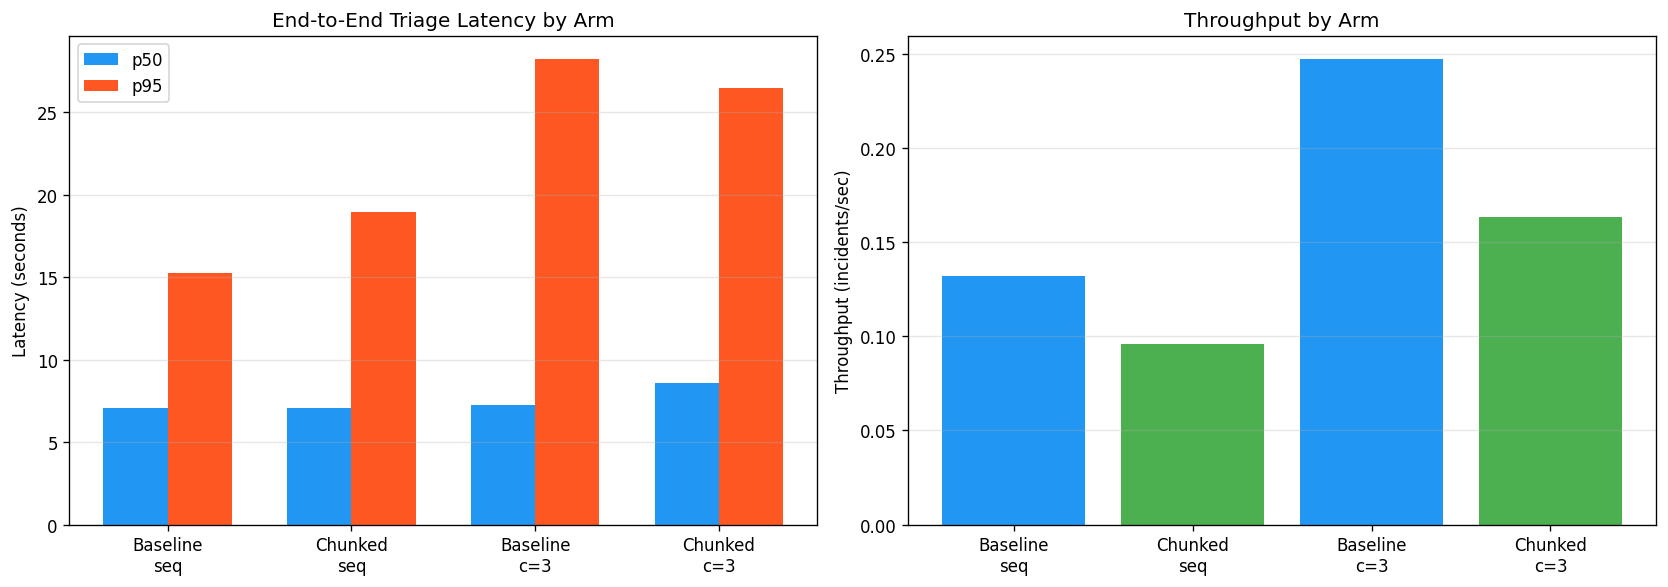

In [2]:
# --- Plot 1: Latency comparison by arm ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# p50 and p95 grouped bar chart
labels = ["Baseline\nseq", "Chunked\nseq", "Baseline\nc=3", "Chunked\nc=3"]
p50s = [r["p50 (s)"] for r in rows]
p95s = [r["p95 (s)"] for r in rows]

x = range(len(labels))
w = 0.35
axes[0].bar([i - w/2 for i in x], p50s, w, label="p50", color="#2196F3")
axes[0].bar([i + w/2 for i in x], p95s, w, label="p95", color="#FF5722")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Latency (seconds)")
axes[0].set_title("End-to-End Triage Latency by Arm")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Throughput comparison
throughputs = [r["Throughput (inc/s)"] for r in rows]
colors = ["#2196F3", "#4CAF50", "#2196F3", "#4CAF50"]
axes[1].bar(labels, throughputs, color=colors)
axes[1].set_ylabel("Throughput (incidents/sec)")
axes[1].set_title("Throughput by Arm")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/latency_comparison.png", bbox_inches="tight")
plt.show()

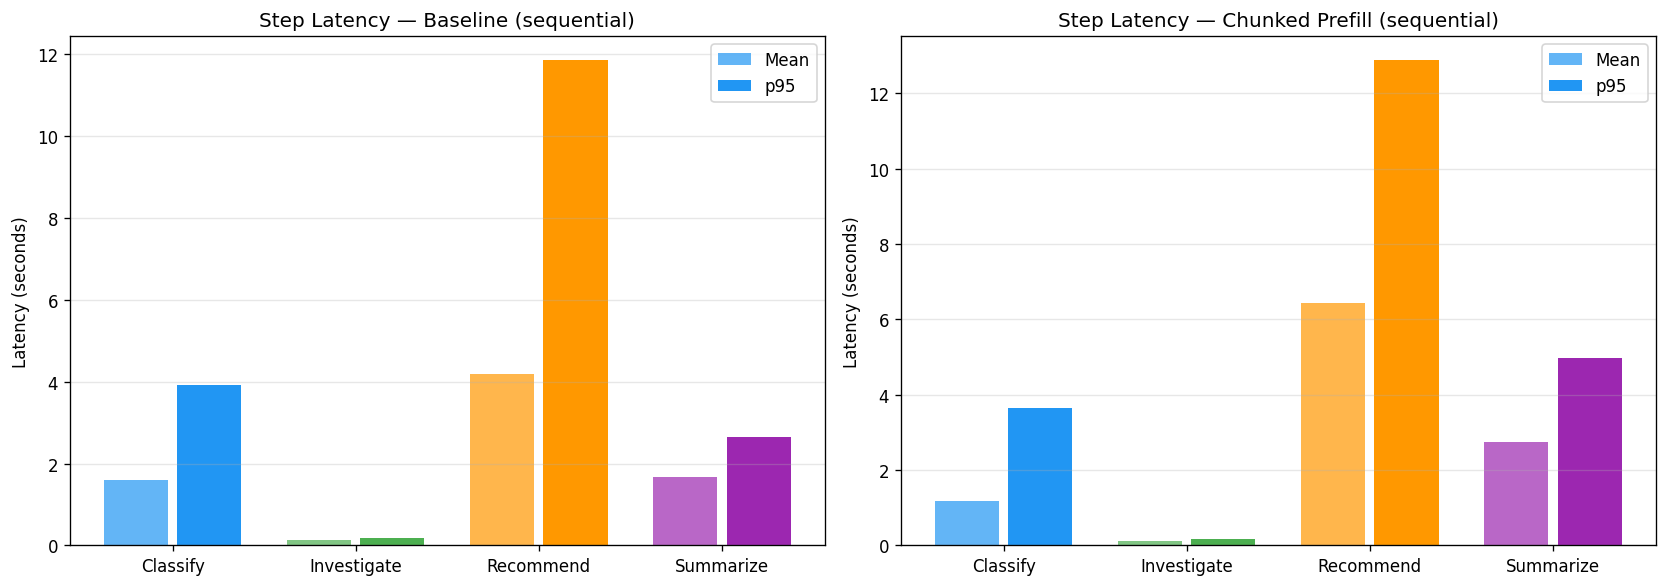

In [3]:
# --- Plot 2: Per-step latency breakdown (sequential arms only) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

steps = ["classify", "investigate", "recommend", "summarize"]
step_colors = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0"]

for idx, (arm_name, arm_label) in enumerate([("baseline_seq", "Baseline (sequential)"), ("chunked_seq", "Chunked Prefill (sequential)")]):
    step_latencies = arms[arm_name]["summary"]["step_latencies"]
    means = [step_latencies.get(s, {}).get("mean", 0) for s in steps]
    p95s = [step_latencies.get(s, {}).get("p95", 0) for s in steps]
    
    x = range(len(steps))
    axes[idx].bar([i - 0.2 for i in x], means, 0.35, label="Mean", color=step_colors, alpha=0.7)
    axes[idx].bar([i + 0.2 for i in x], p95s, 0.35, label="p95", color=step_colors, alpha=1.0)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels([s.capitalize() for s in steps])
    axes[idx].set_ylabel("Latency (seconds)")
    axes[idx].set_title(f"Step Latency — {arm_label}")
    axes[idx].legend()
    axes[idx].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/step_latency.png", bbox_inches="tight")
plt.show()

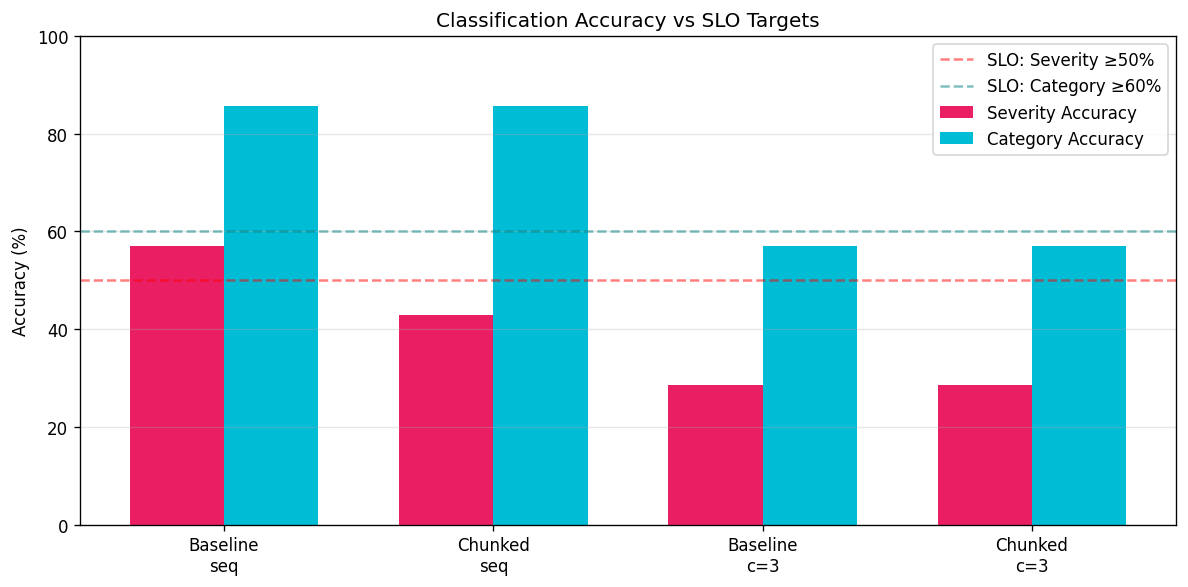

In [4]:
# --- Plot 3: Classification accuracy ---
fig, ax = plt.subplots(figsize=(10, 5))

labels = ["Baseline\nseq", "Chunked\nseq", "Baseline\nc=3", "Chunked\nc=3"]
sev_accs = [arms[k]["summary"]["classification_accuracy"]["severity_accuracy"] * 100 for k in arms]
cat_accs = [arms[k]["summary"]["classification_accuracy"]["category_accuracy"] * 100 for k in arms]

x = range(len(labels))
w = 0.35
ax.bar([i - w/2 for i in x], sev_accs, w, label="Severity Accuracy", color="#E91E63")
ax.bar([i + w/2 for i in x], cat_accs, w, label="Category Accuracy", color="#00BCD4")
ax.axhline(y=50, color="red", linestyle="--", alpha=0.5, label="SLO: Severity ≥50%")
ax.axhline(y=60, color="teal", linestyle="--", alpha=0.5, label="SLO: Category ≥60%")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Classification Accuracy vs SLO Targets")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/classification_accuracy.png", bbox_inches="tight")
plt.show()

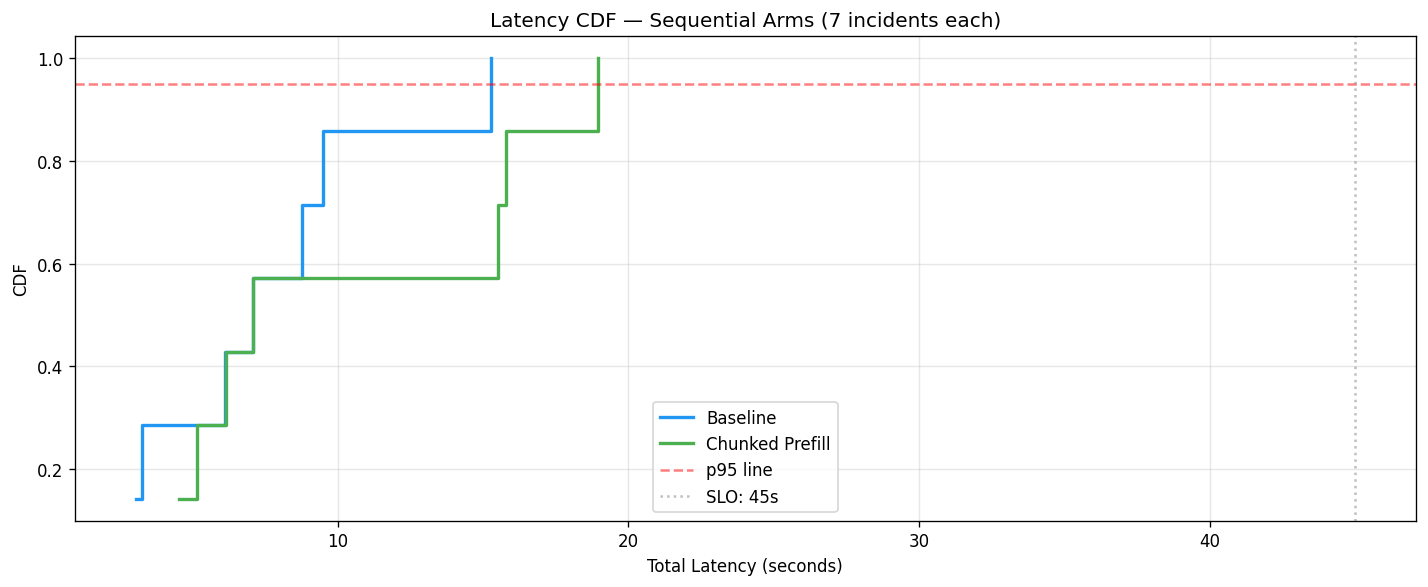

In [5]:
# --- Plot 4: Per-incident latency distribution (baseline sequential) ---
fig, ax = plt.subplots(figsize=(12, 5))

for arm_name, color, label in [("baseline_seq", "#2196F3", "Baseline"), ("chunked_seq", "#4CAF50", "Chunked Prefill")]:
    reports = arms[arm_name]["reports"]
    latencies = sorted([r["total_latency"] for r in reports if r["success"]])
    cdf = [(i + 1) / len(latencies) for i in range(len(latencies))]
    ax.step(latencies, cdf, where="post", label=label, color=color, linewidth=2)

ax.axhline(y=0.95, color="red", linestyle="--", alpha=0.5, label="p95 line")
ax.axvline(x=45, color="gray", linestyle=":", alpha=0.5, label="SLO: 45s")
ax.set_xlabel("Total Latency (seconds)")
ax.set_ylabel("CDF")
ax.set_title("Latency CDF — Sequential Arms (7 incidents each)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figures/latency_cdf.png", bbox_inches="tight")
plt.show()

---

## 3. Model and Instance Justification

### Model: Nemotron Nano 3 30B (nvfp4)

**Why this model:**
- **Instruction following:** Nemotron 30B reliably follows structured output formats (SEVERITY/CATEGORY/CONFIDENCE) needed for the classify step. Our data shows **86% category accuracy** on the golden set (sequential baseline).
- **Context handling:** 4096 token context window is sufficient for the recommend step (~800 tokens with injected tool results).
- **nvfp4 quantization:** Fits in ~15GB VRAM, leaving headroom for KV cache and batching on the 96GB RTX 6000 Pro.
- **License:** NVIDIA open model license, suitable for academic and research use.

**Fallback model if SLO fails:**
- If p95 latency exceeds 45s SLO: switch to **Nemotron Mini 4B** — 8x smaller, ~2x faster inference, at the cost of classification accuracy (expect ~50% category accuracy).
- If accuracy drops below SLO: switch to **Llama 3.1 70B** with tensor parallelism — better reasoning but requires multi-GPU or larger instance.

### Instance: RTX 6000 Pro Blackwell 96GB (Jarvis, owned)

**Why this GPU:**
- **96GB VRAM** allows Nemotron 30B nvfp4 with large KV cache — no OOM risk even at concurrency=3.
- **LAN latency** to gesserit is <1ms, eliminating tunnel overhead as a variable.
- **Owned hardware** — $0/hr operational cost. Amortized cost is fixed regardless of experiment count, enabling unlimited iteration.

**What breaks if we drop VRAM/tier:**
- **24GB GPU (A10/3090):** Nemotron 30B nvfp4 would not fit. Must drop to 4B model or use aggressive quantization.
- **48GB GPU (A6000):** Would fit but with reduced KV cache. Concurrency=3 might cause OOM under batch inference.
- **Cloud A100 80GB:** Would work but adds SSH tunnel latency (~5-15ms) and $1.29/hr cost.

### Production Knobs

| Scenario | Action |
|----------|--------|
| p95 latency too high | Reduce `--max-model-len` to free KV cache; reduce concurrency |
| Accuracy too low | Switch model (larger or fine-tuned); improve prompts with more examples |
| Scale out needed | Add second vLLM backend in `config.yaml`; nginx round-robin across backends |
| Cost optimization | Switch to Nemotron Mini 4B for non-critical incidents; route via `X-Technique` |

---

## 4. Dashboard

### Grafana Dashboard: Inference Gateway Overview

16-panel dashboard covering the full request path. Prometheus scrapes gateway metrics at `:9101` every 15s.

**Layer coverage:**
- **Gateway layer** (`llm_gateway_*` metrics on :9101): Request rate, duration histograms, TTFT, token rates, error rate, cost estimation
- **vLLM layer** (optional scrape via :8081): GPU utilization, model throughput (not shown — Jarvis reached directly on LAN, no tunnel metrics port exposed)
- **Agent layer**: Classification accuracy, per-step latencies (from committed JSON results, plotted above)

**Key panels:**
1. Request Rate by technique (req/s)
2. Request Duration p50/p95/p99 by technique
3. Error Rate (total request rate)
4. Token Rate (prompt + completion tok/s)
5. Stat panels: Total Requests, Prompt Tokens, Completion Tokens, Avg Tokens/sec, Avg TTFT, GPU Cost
6. Time to First Token p50/p95 (streaming requests)
7. Time per Output Token p50/p95
8. Completion Tokens/sec by technique
9. Inter-Chunk Delay p50/p95
10. Requests by Technique (pie chart)
11. Estimated GPU Cost Over Time

Dashboard JSON export: `monitoring/grafana/dashboards/gateway-overview.json`  
Prometheus config: `monitoring/prometheus.yml`

![Dashboard Screenshot](figures/dashboard.png)

*Screenshot taken after running all 6 experiment arms (4 triage + 2 benchmark). Note the technique-separated latency curves and the request rate spikes corresponding to each arm.*

---

## 5. Reproducibility

### Clone and Run

```bash
git clone <repo-url>
cd inference-gateway

# 1. Configure environment
cp .env.example .env
# Edit .env: set GPU_HOURLY_COST_USD, SSH_HOST if using tunnel

# 2. Update config.yaml to point at your vLLM backend
# default: vllm_jarvis at http://jarvis.swesty.net:8000

# 3. Start the gateway + monitoring stack
uv sync
uv run python app.py &          # Gateway on :8080, metrics on :9101
docker compose up -d prometheus grafana nginx  # Monitoring + LB

# 4. Start vLLM on GPU host (Jarvis)
# ssh jarvis
# VLLM_MODEL=nvidia/Nemotron-Nano-3-30B-nvfp4 bash scripts/vllm_engine/baseline.sh

# 5. Run the triage agent
cd workloads && uv sync
uv run python -m triage_agent \
  --model nemotron-lora \
  --concurrency 1 \
  --output results/triage_results.json

# 6. Run benchmarks
cd .. && uv run python scripts/benchmark.py \
  --requests 30 --concurrency 5 \
  --technique baseline --model nemotron-lora
```

### Key Environment Variables (`.env.example`)
- `PORT=8080` — Gateway listen port
- `GPU_HOURLY_COST_USD=0.0` — Set for owned hardware, or Lambda rate
- `VLLM_SERVER_PROFILE=default` — Metrics label
- `VLLM_AUTO_ENGINE_ROUTING=true` — Auto port-offset for engine fleet
- `GATEWAY_METRICS_LOG_DIR=logs/gateway` — JSONL request logs

### Scripts Used
- `scripts/vllm_engine/baseline.sh` — vLLM with default config
- `scripts/vllm_engine/chunked_prefill.sh` — vLLM with `--enable-chunked-prefill`
- `scripts/benchmark.py` — Raw throughput benchmark
- `workloads/triage_agent/` — Full agentic workload